In [11]:
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
import data_preprocessing.plotting_functions as ABC_plot
import data_preprocessing.ABC_priors_and_functions as ABC
import data_preprocessing.stochastic_systems_models as SSM

SMALL_SIZE = 12
MEDIUM_SIZE = 12
BIGGER_SIZE = 16

plt.rc('font', size=BIGGER_SIZE)          # controls default text sizes
plt.rc('axes', titlesize=BIGGER_SIZE)     # fontsize of the axes title
plt.rc('axes', labelsize=BIGGER_SIZE)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('ytick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('legend', fontsize=SMALL_SIZE)    # legend fontsize
plt.rc('figure', titlesize=BIGGER_SIZE)  # fontsize of the figure title
plt.rcParams['font.family'] = 'Arial'

In [4]:
#Extracting posterior parameters
params = np.load("C:\\Uni\\Imperial\\Year 1\\First_pet_project\\Project4\\extended_three_pop_ABC\\accepted_extended_three_population_chase_pulse_params.npy")
beta0, beta1, p, mu_d_r, mu_d_y, mu_d_o, mu_a, mu_r, mu_rej, c = params.transpose()

mu_b = np.zeros(len(beta0))
mu_b[mu_d_o != 0] = ((mu_d_r+p*mu_r)*(mu_d_y*mu_d_o + mu_d_y*mu_rej+mu_d_o*mu_a)/((mu_d_o+mu_rej)*(mu_r-mu_d_r)))[mu_d_o != 0]
mu_b[mu_d_o == 0] = ((mu_d_r+p*mu_r)*mu_d_y/(mu_r-mu_d_r))[mu_d_o == 0]

f_y = 1/(1 + mu_b/(mu_d_r + p*mu_r) + mu_a/(mu_d_o + mu_rej))
f_r = (mu_b/(mu_d_r + p*mu_r))*1/(1 + mu_b/(mu_d_r + p*mu_r) + mu_a/(mu_d_o + mu_rej))
f_o = 1-f_y-f_r

pi_y = 1/(1 + (1+p)*mu_b*mu_r/(mu_d_r+p*mu_r)**2 + mu_a*mu_rej/(mu_d_o + mu_rej)**2)

mu_coal =  2 * (pi_y/f_y)**2 * f_r * (mu_r + mu_d_r*p)/(mu_r*p + mu_d_r) * mu_r

m = mu_rej/(mu_rej+mu_d_o)

param = params[69]*1
param[-1]= 0.05

param_mixed = params[180]*1
param_mixed[-1]= 0.05

def plot_populations(population_sizes):
    fig, ax = plt.subplots(2,4, figsize = (15,6))
    for i in range(population_sizes.shape[0]):
        ax[0,0].plot(population_sizes[i,:,0]+population_sizes[i,:,3], color= "black", alpha = 0.05)
        ax[0,1].plot(population_sizes[i,:,1]+population_sizes[i,:,4], color= "black", alpha = 0.05)
        ax[0,2].plot(population_sizes[i,:,2]+population_sizes[i,:,5], color= "black", alpha = 0.05)
        ax[0,3].plot(np.sum(population_sizes[i,:,:], axis = 1), color= "black", alpha = 0.05)
        ax[1,0].plot(population_sizes[i,:,3]/(population_sizes[i,:,0]+population_sizes[i,:,3]), color= "black", alpha = 0.05)
        ax[1,1].plot(population_sizes[i,:,4]/(population_sizes[i,:,1]+population_sizes[i,:,4]), color= "black", alpha = 0.05)
        ax[1,2].plot(population_sizes[i,:,5]/(population_sizes[i,:,2]+population_sizes[i,:,5]), color= "black", alpha = 0.05)
        ax[1,3].plot((population_sizes[i,:,3]+population_sizes[i,:,4]+population_sizes[i,:,5])/np.sum(population_sizes[i,:,:], axis = 1), color= "black", alpha = 0.05)

    ax[0,0].plot(np.mean(population_sizes[:,:,0]+population_sizes[:,:,3], axis=0), color= "blue", linewidth = 2)
    ax[0,1].plot(np.mean(population_sizes[:,:,1]+population_sizes[:,:,4], axis=0), color= "blue", linewidth = 2)
    ax[0,2].plot(np.mean(population_sizes[:,:,2]+population_sizes[:,:,5], axis=0), color= "blue", linewidth = 2)
    ax[0,3].plot(np.mean(np.sum(population_sizes[:,:,:], axis = 2), axis=0), color= "blue", linewidth = 3, label = "Mean")
    A=population_sizes[:,:,3]/(population_sizes[:,:,0]+population_sizes[:,:,3])
    A[np.isnan(A)] = 0
    ax[1,0].plot(np.mean(A, axis=0), color= "blue", linewidth = 2)
    ax[1,1].plot(np.mean(population_sizes[:,:,4]/(population_sizes[:,:,1]+population_sizes[:,:,4]), axis=0), color= "blue", linewidth = 2)
    ax[1,2].plot(np.mean(population_sizes[:,:,5]/(population_sizes[:,:,2]+population_sizes[:,:,5]), axis=0), color= "blue", linewidth = 2)
    ax[1,3].plot(np.mean((population_sizes[:,:,3]+population_sizes[:,:,4]+population_sizes[:,:,5])/np.sum(population_sizes[i,:,:], axis = 1), axis=0), color= "blue", linewidth = 3)
    
    ax[0,3].plot([], color= "black", alpha = 0.2, label = "Individual simulations")
    ax[0,3].legend()

    fig.text(0.5, 0.04, 'Time (h)', ha='center')
    ax[0,0].set_ylabel("MtDNA number")
    ax[1,0].set_ylabel("Heteroplasmy")
    ax[0,0].set_title("Replicating")
    ax[0,1].set_title("Active")
    ax[0,2].set_title("Inactive")
    ax[0,3].set_title("Combined")

We add 100 exogenous mtDNA to the active or inactive population and observe their heteroplasmy, and the out-of-equilibrium behaviour of the cell. We observe that the heteroplasmy is far likely to increase if the exogenous mtDNA is added to the active subpopulation than the inactive (at least for this parameterisation, which has small levels of mixing $m_q$)

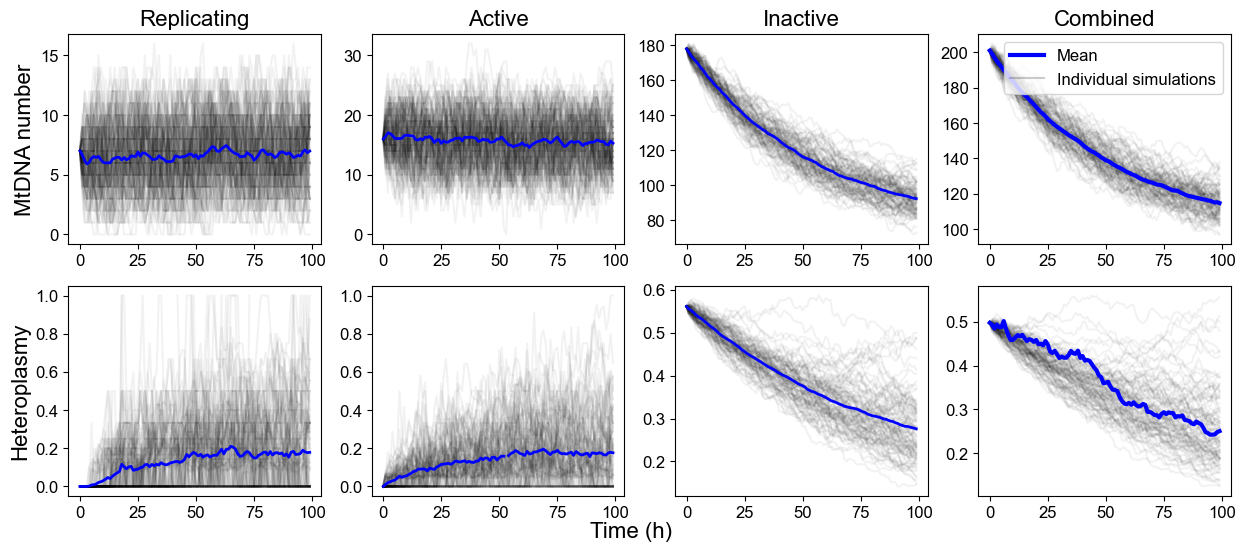

In [ ]:
#simulating adding 100 DNA to the inactive population
population_sizes = SSM.extended_three_population_SSD_fixation_prob_tracked(param, time=100,num_iter = 100, N=100, delta = 1, initial_active_num=0, initial_inactive_num=100, mode = "non equilibrium")
plot_populations(population_sizes)

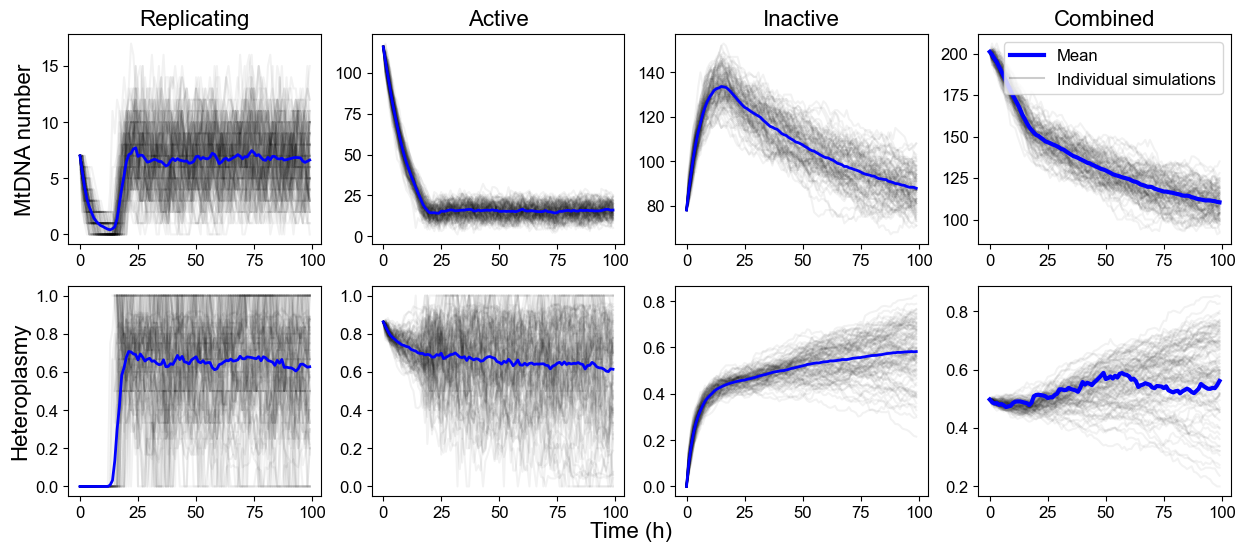

In [ ]:
#simulating adding 100 DNA to the active population
population_sizes = SSM.extended_three_population_SSD_fixation_prob_tracked(param, time=100,num_iter = 100, N=100, delta = 1, initial_active_num=100, initial_inactive_num=0, mode = "non equilibrium")
plot_populations(population_sizes)

We can, more formally, output a fixation probability from these simulations by simulating until the exogenous mtDNA either fixes or dies out, and computing the proportion of simulations for which it fixes. We do this for the active vs inactive populations, for a high mixing vs low mixing parameterisation.

Each block can take a few minutes to run.

In [9]:
#100 added to the inactive, low mixing param
num_iter=100
fixed_arr, final_states = SSM.extended_three_population_SSD_fixation_prob(param, num_iter = num_iter, N=100, delta = 1, pref_deg_factor = 1, initial_active_num = 0, initial_inactive_num=100, mode = "non equilibrium")
p=np.sum(fixed_arr)/num_iter
print(f"Proportion fixed (100 added to the inactive, low mixing param): {p:.3f} +/- {np.sqrt(p*(1-p)/num_iter):.3f}")

Proportion fixed (100 added to the inactive, low mixing param): 0.200 +/- 0.040


In [ ]:
#100 added to the active, low mixing param
num_iter=100
fixed_arr, final_states = SSM.extended_three_population_SSD_fixation_prob(param, num_iter = num_iter, N=100, delta = 1, pref_deg_factor = 1, initial_active_num = 100, initial_inactive_num=0, mode = "non equilibrium")
p=np.sum(fixed_arr)/num_iter
print(f"Proportion fixed (100 added to the active, low mixing param): {p:.3f} +/- {np.sqrt(p*(1-p)/num_iter):.3f}")

Proportion fixed (100 added to the active, low mixing param): 0.666 +/- 0.021


In [8]:
#100 added to the inactive, high mixing param
num_iter=50
fixed_arr, final_states = SSM.extended_three_population_SSD_fixation_prob(param_mixed, num_iter = num_iter, N=100, delta = 1, pref_deg_factor = 1, initial_active_num = 0, initial_inactive_num=100, mode = "non equilibrium", verbose=False)
p=np.sum(fixed_arr)/num_iter
print(f"Proportion fixed (100 added to the inactive, high mixing param): {p:.3f} +/- {np.sqrt(p*(1-p)/num_iter):.3f}")

Proportion fixed (100 added to the inactive, high mixing param): 0.520 +/- 0.071


In [7]:
#100 added to the active, high mixing param
num_iter=50
fixed_arr, final_states = SSM.extended_three_population_SSD_fixation_prob(param_mixed, num_iter = num_iter, N=100, delta = 1, pref_deg_factor = 1, initial_active_num = 100, initial_inactive_num=0, mode = "non equilibrium", verbose=False)
p=np.sum(fixed_arr)/num_iter
print(f"Proportion fixed (100 added to the active, high mixing param): {p:.3f} +/- {np.sqrt(p*(1-p)/num_iter):.3f}")

Proportion fixed (100 added to the active, high mixing param): 0.400 +/- 0.069


We see that when mixing is high, there is not that much difference betwen the fixation probability when exogenous mtDNA is added to the active vs inactive populations. When mixing is low, however, there is a far greater discrepency, with a higher fixation probability when added to the active population.

When repeating the above procedure for every posterior parameter, with num_iter=10,000, and for two different starting exogenous mtDNA heteroplasmies, we obtain the following:

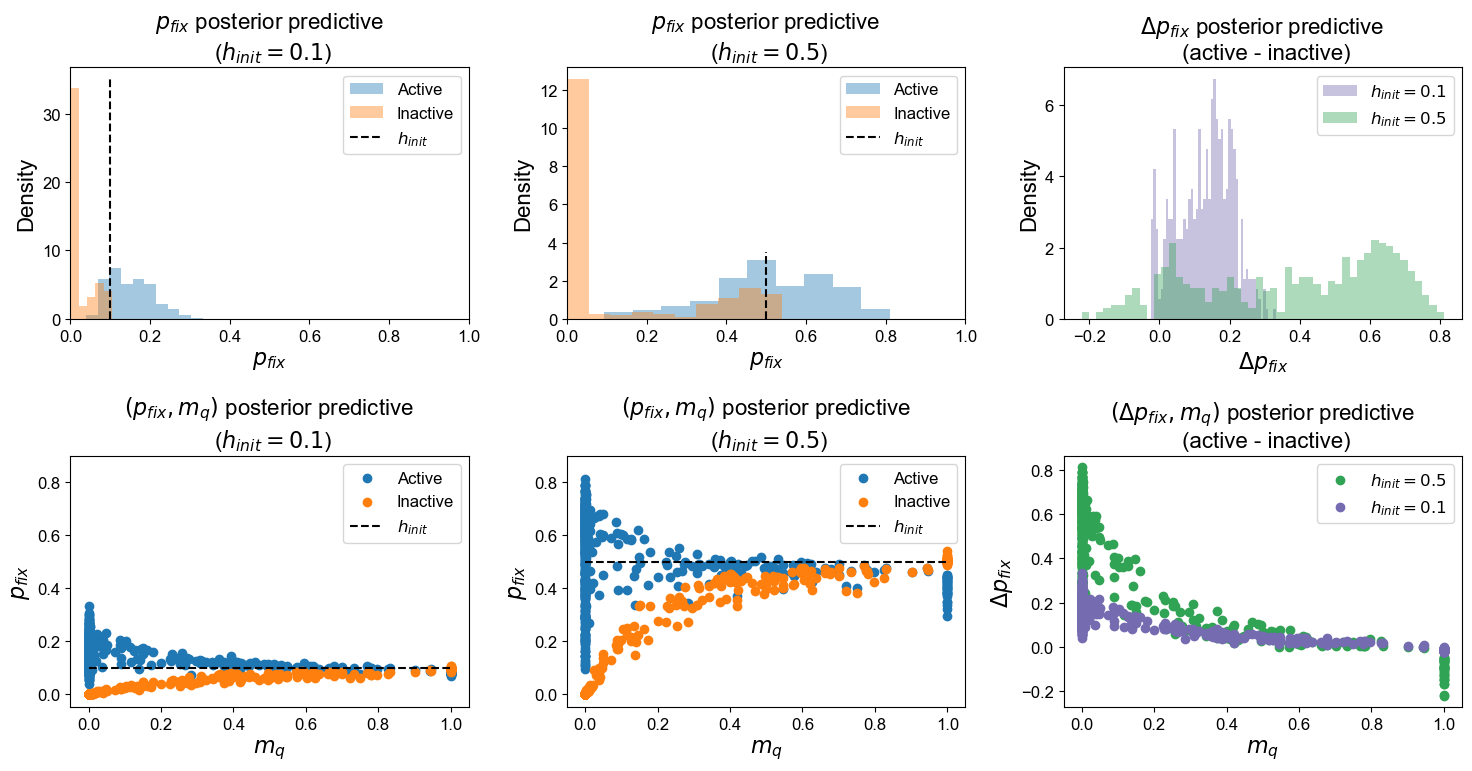

In [12]:
fixs_10_active = np.load("./data_preprocessing/exogenous_mtDNA_data/fixs_10_active_subcontrol.npy")/10000
fixs_10_inactive = np.load("./data_preprocessing/exogenous_mtDNA_data/fixs_10_inactive_subcontrol.npy")/10000
fixs_50_active = np.load("./data_preprocessing/exogenous_mtDNA_data/fixs_50_active_subcontrol.npy")/10000
fixs_50_inactive = np.load("./data_preprocessing/exogenous_mtDNA_data/fixs_50_inactive_subcontrol.npy")/10000
import matplotlib.colors as mcolors
cmap = plt.get_cmap('tab20c')

# Extract all 20 colors as hex codes
hex_colors = [mcolors.to_hex(cmap(i)) for i in range(20)]

fix, ax = plt.subplots(2,3, figsize = (15,8))
ax[0,0].hist(fixs_10_active, density = True, alpha = 0.4, label = "Active")
ax[0,0].hist(fixs_10_inactive, density = True, alpha = 0.4, bins = 5, label = "Inactive")
ax[0,1].hist(fixs_50_active, density=True, alpha=0.4, label = "Active")
ax[0,1].hist(fixs_50_inactive, density=True, alpha=0.4, label = "Inactive")
ax[0,2].hist(fixs_10_active-fixs_10_inactive, density=True, bins = 50, alpha = 0.4, color = hex_colors[12], label = "$h_{init} = 0.1$")
ax[0,2].hist(fixs_50_active-fixs_50_inactive, density=True, bins = 50, alpha = 0.4, color = hex_colors[8], label = "$h_{init} = 0.5$")
ax[0,0].set_xlim(0,1)
ax[0,1].set_xlim(0,1)

ax[1,0].scatter(m, fixs_10_active, label = "Active")
ax[1,0].scatter(m, fixs_10_inactive, label = "Inactive")
ax[1,1].scatter(m, fixs_50_active, label = "Active")
ax[1,1].scatter(m, fixs_50_inactive, label = "Inactive")
ax[1,2].scatter(m, fixs_50_active-fixs_50_inactive, color = hex_colors[8], label = "$h_{init} = 0.5$")
ax[1,2].scatter(m, fixs_10_active-fixs_10_inactive, color = hex_colors[12], label = "$h_{init} = 0.1$")
ax[1,0].set_ylim(-0.05,0.9)
ax[1,1].set_ylim(-0.05,0.9)
ax[0,0].vlines(0.1, 0,35, colors = "black", linestyles = "dashed", label = "$h_{init}$")
ax[0,1].vlines(0.5, 0,3.5, colors = "black", linestyles = "dashed", label = "$h_{init}$")

ax[1,0].hlines(0.1, 0,1, colors = "black", linestyles = "dashed", label = "$h_{init}$")
ax[1,1].hlines(0.5, 0,1, colors = "black", linestyles = "dashed", label = "$h_{init}$")
for i in range(2):
    for j in range(3):
        ax[i,j].legend()
        if i == 0:
            ax[i,j].set_xlabel("$p_{fix}$")
            ax[i,j].set_ylabel("Density")
        elif i == 1:
            ax[i,j].set_xlabel("$m_q$")
            ax[i,j].set_ylabel("$p_{fix}$")


ax[0,2].set_xlabel("$\Delta p_{fix}$")
ax[1,2].set_ylabel("$\Delta p_{fix}$")

ax[0,0].set_title("$p_{fix}$ posterior predictive \n ($h_{init} = 0.1$)")
ax[0,1].set_title("$p_{fix}$ posterior predictive \n ($h_{init} = 0.5$)")
ax[0,2].set_title("$\Delta p_{fix}$ posterior predictive \n (active - inactive)")

ax[1,0].set_title("$(p_{fix}, m_q)$ posterior predictive \n ($h_{init} = 0.1$)")
ax[1,1].set_title("$(p_{fix}, m_q)$ posterior predictive \n ($h_{init} = 0.5$)")
ax[1,2].set_title("$(\Delta p_{fix}, m_q)$ posterior predictive \n (active - inactive)")
plt.tight_layout()